In [1]:
import pandas as pd
import numpy as np


In [2]:

df = pd.read_csv("DS-MASPD.tsv", sep="\t")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Dataset loaded successfully!
Number of rows: 1795
Number of columns: 98


In [ ]:

df.head()


,processid,sampleid,fieldid,museumid,record_id,specimenid,processid_minted_date,bin_uri,bin_created_date,collection_code,...,specimendetails.verbatim_collectiondate_start,specimendetails.verbatim_sampling_protocol,specimendetails.verbatim_tissuetype,specimendetails.verbatim_class,specimendetails.verbatim_family,specimendetails.verbatim_genus,specimendetails.verbatim_identifier,specimendetails.verbatim_order,specimendetails.verbatim_phylum,specimendetails.verbatim_species
0,AMSPK001-15,UOS-AMSPK-00001,UOS-AMSPK-00001,NaN,AMSPK001-15.COI-5P,6122892,2015-07-07,BOLD:ABX7398,2012-07-13,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AMSPK003-15,UOS-AMSPK-00003,UOS-AMSPK-00003,NaN,AMSPK003-15.COI-5P,6122894,2015-07-07,BOLD:ABX7398,2012-07-13,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AMSPK004-15,UOS-AMSPK-00004,UOS-AMSPK-00004,NaN,AMSPK004-15.COI-5P,6122895,2015-07-07,BOLD:ABX7398,2012-07-13,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AMSPK005-15,UOS-AMSPK-00005,UOS-AMSPK-00005,NaN,AMSPK005-15.COI-5P,6122896,2015-07-07,BOLD:ABX7398,2012-07-13,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AMSPK006-15,UOS-AMSPK-00006,UOS-AMSPK-00006,NaN,AMSPK006-15.COI-5P,6122897,2015-07-07,BOLD:AEB1907,2020-02-03,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:

print(df.columns.tolist())


['processid', 'sampleid', 'fieldid', 'museumid', 'record_id', 'specimenid', 'processid_minted_date', 'bin_uri', 'bin_created_date', 'collection_code', 'inst', 'sovereign_inst', 'taxid', 'kingdom', 'phylum', 'class', 'order', 'family', 'subfamily', 'tribe', 'genus', 'species', 'subspecies', 'species_reference', 'identification', 'identification_method', 'identification_rank', 'identified_by', 'identifier_email', 'taxonomy_notes', 'sex', 'reproduction', 'life_stage', 'short_note', 'notes', 'voucher_type', 'tissue_type', 'specimen_linkout', 'associated_specimens', 'associated_taxa', 'collectors', 'collection_date_start', 'collection_date_end', 'collection_event_id', 'collection_time', 'collection_notes', 'geoid', 'country/ocean', 'country_iso', 'province/state', 'region', 'sector', 'site', 'site_code', 'coord', 'coord_accuracy', 'coord_source', 'elev', 'elev_accuracy', 'depth', 'depth_accuracy', 'realm', 'biome', 'ecoregion', 'habitat', 'sampling_protocol', 'nuc', 'nuc_basecount', 'insdc_

In [ ]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1795 entries, 0 to 1794
Data columns (total 98 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   processid                                       1795 non-null   str    
 1   sampleid                                        1795 non-null   str    
 2   fieldid                                         470 non-null    str    
 3   museumid                                        1542 non-null   str    
 4   record_id                                       1795 non-null   str    
 5   specimenid                                      1795 non-null   int64  
 6   processid_minted_date                           1795 non-null   str    
 7   bin_uri                                         1784 non-null   str    
 8   bin_created_date                                1784 non-null   str    
 9   collection_code                                 1255

In [6]:

important_columns = [
    "processid",
    "species",
    "identification_rank",
    "nuc",
    "nuc_basecount",
    "marker_code"
]

df[important_columns].head(10)


,processid,species,identification_rank,nuc,nuc_basecount,marker_code
0,AMSPK001-15,Draposa oakleyi,species,--------------------------------cTATAATAGGTACT...,626,COI-5P
1,AMSPK003-15,Draposa oakleyi,species,TACTTTATATTTAATATTTGGAGTTTGATCGGCTATAATAGGTACT...,658,COI-5P
2,AMSPK004-15,Draposa oakleyi,species,TACTTTATATTTAATATTTGGAGTTTGATCGGCTATAATAGGTACT...,658,COI-5P
3,AMSPK005-15,Draposa oakleyi,species,TACTTTATATTTAATATTTGGAGTTTGATCGGCTATAATAGGTACT...,658,COI-5P
4,AMSPK006-15,Wadicosa fidelis,species,AACGTTATATTTAATATTTGGTGTTTGATCGGCTATAATGGGAACT...,658,COI-5P
5,AMSPK007-15,Wadicosa fidelis,species,AACGTTATATTTAATATTTGGTGTTTGATCGGCTATAATGGGAACT...,658,COI-5P
6,AMSPK008-15,Wadicosa fidelis,species,AACGTTATATTTAATATTTGGTGTTTGATCGGCTATAATGGGAACT...,658,COI-5P
7,AMSPK009-15,Wadicosa fidelis,species,AACGTTATATTTAATATTTGGTGTTTGATCGGCTATAATGGGAACT...,658,COI-5P
8,AMSPK010-15,Wadicosa fidelis,species,AACGTTATATTTAATATTTGGTGTTTGATCGGCTATAATGGGAACT...,658,COI-5P
9,AMSPK011-15,Lycosa terrestris,species,AACTTTATATTTAATGTTTGGGGTTTGATCGGCTATAATAGGTACT...,658,COI-5P


In [7]:

print("Number of unique species labels:", df["species"].nunique())

print("\nMost common species:")
print(df["species"].value_counts().head(15))


Number of unique species labels: 201

Most common species:
species
Neoscona theisi          160
Oxyopes hindostanicus    123
Oxyopes azhari           112
Wadicosa fidelis          75
Cyrtophora citricola      66
Thyene imperialis         56
Oxyopes oryzae            52
Lycosa terrestris         45
Tetragnatha javana        43
Runcinia insecta          42
Plexippus paykulli        41
Eriovixia excelsa         40
Neoscona vigilans         38
Thomisus zaheeri          31
Leucauge decorata         30
Name: count, dtype: int64


In [8]:

# Select five target species
target_species = [
    "Neoscona theisi",
    "Oxyopes hindostanicus",
    "Oxyopes azhari",
    "Wadicosa fidelis",
    "Oxyopes oryzae"
]

# Keep only records belonging to our target species
df_subset = df[df["species"].isin(target_species)].copy()

print("Original dataset shape:", df.shape)
print("Selected dataset shape:", df_subset.shape)

print("\nRecords per species:")
print(df_subset["species"].value_counts())


Original dataset shape: (1795, 98)
Selected dataset shape: (522, 98)

Records per species:
species
Neoscona theisi          160
Oxyopes hindostanicus    123
Oxyopes azhari           112
Wadicosa fidelis          75
Oxyopes oryzae            52
Name: count, dtype: int64


In [9]:

# Keep the columns needed for our project
df_subset = df_subset[
    ["processid", "species", "nuc", "marker_code"]
].copy()

# Convert DNA sequences to uppercase
df_subset["sequence"] = (
    df_subset["nuc"]
    .fillna("")
    .str.upper()
)

# Remove gaps and characters other than A, C, G, T and N
df_subset["sequence"] = df_subset["sequence"].str.replace(
    r"[^ACGTN]", "", regex=True
)

# Remove empty sequences
df_subset = df_subset[df_subset["sequence"] != ""].copy()

print("Records after basic sequence cleaning:", len(df_subset))
print("\nExamples of cleaned sequences:")
df_subset[["species", "sequence"]].head()


Records after basic sequence cleaning: 522

Examples of cleaned sequences:


,species,sequence
4,Wadicosa fidelis,AACGTTATATTTAATATTTGGTGTTTGATCGGCTATAATGGGAACT...
5,Wadicosa fidelis,AACGTTATATTTAATATTTGGTGTTTGATCGGCTATAATGGGAACT...
6,Wadicosa fidelis,AACGTTATATTTAATATTTGGTGTTTGATCGGCTATAATGGGAACT...
7,Wadicosa fidelis,AACGTTATATTTAATATTTGGTGTTTGATCGGCTATAATGGGAACT...
8,Wadicosa fidelis,AACGTTATATTTAATATTTGGTGTTTGATCGGCTATAATGGGAACT...


In [10]:

# Calculate cleaned sequence lengths
df_subset["sequence_length"] = df_subset["sequence"].str.len()

print("Sequence length statistics:")
print(df_subset["sequence_length"].describe())

print(
    "\nSequences containing ambiguous N:",
    df_subset["sequence"].str.contains("N").sum()
)

print(
    "Sequences shorter than 500 bases:",
    (df_subset["sequence_length"] < 500).sum()
)


Sequence length statistics:
count    522.000000
mean     652.339080
std       23.432632
min      451.000000
25%      658.000000
50%      658.000000
75%      658.000000
max      658.000000
Name: sequence_length, dtype: float64

Sequences containing ambiguous N: 8
Sequences shorter than 500 bases: 3


In [11]:

# Retain sufficiently long sequences without ambiguous bases
df_clean = df_subset[
    (df_subset["sequence_length"] >= 500)
    & (~df_subset["sequence"].str.contains("N"))
].copy()

print("Records before quality filtering:", len(df_subset))
print("Records after quality filtering:", len(df_clean))

print("\nRecords per species after filtering:")
print(df_clean["species"].value_counts())


Records before quality filtering: 522
Records after quality filtering: 511

Records per species after filtering:
species
Neoscona theisi          158
Oxyopes hindostanicus    118
Oxyopes azhari           108
Wadicosa fidelis          75
Oxyopes oryzae            52
Name: count, dtype: int64


In [12]:

print("Records before deduplication:", len(df_clean))
print(
    "Unique DNA sequences before deduplication:",
    df_clean["sequence"].nunique()
)

# Keep one record for each exact sequence
df_clean = df_clean.drop_duplicates(
    subset=["sequence"]
).copy()

print("\nRecords after deduplication:", len(df_clean))
print("\nFinal records per species:")
print(df_clean["species"].value_counts())


Records before deduplication: 511
Unique DNA sequences before deduplication: 344

Records after deduplication: 344

Final records per species:
species
Neoscona theisi          102
Oxyopes hindostanicus     75
Oxyopes azhari            71
Wadicosa fidelis          51
Oxyopes oryzae            45
Name: count, dtype: int64


In [13]:

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

print("Scikit-learn version:", sklearn.__version__)


Scikit-learn version: 1.9.0


In [14]:

# DNA sequences are the input (X)
X = df_clean["sequence"].reset_index(drop=True)

# Species labels are the target (y)
y = df_clean["species"].reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training sequences:", len(X_train))
print("Testing sequences:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())


Training sequences: 275
Testing sequences: 69

Training distribution:
species
Neoscona theisi          81
Oxyopes hindostanicus    60
Oxyopes azhari           57
Wadicosa fidelis         41
Oxyopes oryzae           36
Name: count, dtype: int64

Testing distribution:
species
Neoscona theisi          21
Oxyopes hindostanicus    15
Oxyopes azhari           14
Wadicosa fidelis         10
Oxyopes oryzae            9
Name: count, dtype: int64


In [15]:

# Create a vectorizer for overlapping 3-mers
vectorizer_3 = CountVectorizer(
    analyzer="char",
    ngram_range=(3, 3),
    lowercase=False
)

# Learn the vocabulary from training sequences only
X_train_3 = vectorizer_3.fit_transform(X_train)

# Transform test sequences using the same vocabulary
X_test_3 = vectorizer_3.transform(X_test)

print("Training feature matrix:", X_train_3.shape)
print("Testing feature matrix:", X_test_3.shape)

print("\nFirst 20 learned k-mers:")
print(vectorizer_3.get_feature_names_out()[:20])


Training feature matrix: (275, 64)
Testing feature matrix: (69, 64)

First 20 learned k-mers:
['AAA' 'AAC' 'AAG' 'AAT' 'ACA' 'ACC' 'ACG' 'ACT' 'AGA' 'AGC' 'AGG' 'AGT'
 'ATA' 'ATC' 'ATG' 'ATT' 'CAA' 'CAC' 'CAG' 'CAT']


In [16]:

from sklearn.preprocessing import normalize

X_train_3_freq = normalize(X_train_3, norm="l1", axis=1)
X_test_3_freq = normalize(X_test_3, norm="l1", axis=1)

print("Training frequency matrix:", X_train_3_freq.shape)
print("Testing frequency matrix:", X_test_3_freq.shape)

# Inspect the features for the first training sequence
first_sequence_features = pd.DataFrame({
    "kmer": vectorizer_3.get_feature_names_out(),
    "frequency": X_train_3_freq.toarray()[0]
})

print("\nMost frequent 3-mers in the first sequence:")
print(
    first_sequence_features
    .sort_values("frequency", ascending=False)
    .head(10)
)


Training frequency matrix: (275, 64)
Testing frequency matrix: (69, 64)

Most frequent 3-mers in the first sequence:
   kmer  frequency
15  ATT   0.077744
63  TTT   0.076220
51  TAT   0.060976
60  TTA   0.060976
3   AAT   0.033537
12  ATA   0.030488
35  GAT   0.027439
48  TAA   0.025915
50  TAG   0.024390
62  TTG   0.024390


In [17]:

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd


In [18]:

results = []
trained_models = {}
vectorizers = {}

for k in [3, 4, 5]:

    print(f"\n{'=' * 50}")
    print(f"Evaluating k = {k}")
    print(f"{'=' * 50}")

    # Extract k-mer features using training data only
    vectorizer = CountVectorizer(
        analyzer="char",
        ngram_range=(k, k),
        lowercase=False
    )

    X_train_k = vectorizer.fit_transform(X_train)
    X_test_k = vectorizer.transform(X_test)

    # Normalize each sequence's k-mer counts
    X_train_k = normalize(X_train_k, norm="l1", axis=1)
    X_test_k = normalize(X_test_k, norm="l1", axis=1)

    models = {
        "Logistic Regression": LogisticRegression(
            max_iter=2000,
            random_state=42
        ),
        "Multinomial Naive Bayes": MultinomialNB(),
        "Random Forest": RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        )
    }

    vectorizers[k] = vectorizer

    for model_name, model in models.items():

        model.fit(X_train_k, y_train)
        y_pred = model.predict(X_test_k)

        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(
            y_test, y_pred, average="macro", zero_division=0
        )
        recall = recall_score(
            y_test, y_pred, average="macro", zero_division=0
        )
        f1 = f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )

        results.append({
            "k": k,
            "Model": model_name,
            "Accuracy": accuracy,
            "Macro Precision": precision,
            "Macro Recall": recall,
            "Macro F1": f1,
            "Number of features": X_train_k.shape[1]
        })

        trained_models[(k, model_name)] = model

        print(
            f"{model_name}: "
            f"Accuracy={accuracy:.3f}, "
            f"Macro F1={f1:.3f}"
        )

results_df = pd.DataFrame(results)

print("\nAll experiment results:")
results_df.round(3)



Evaluating k = 3
Logistic Regression: Accuracy=0.304, Macro F1=0.093
Multinomial Naive Bayes: Accuracy=0.304, Macro F1=0.093
Random Forest: Accuracy=1.000, Macro F1=1.000

Evaluating k = 4
Logistic Regression: Accuracy=0.304, Macro F1=0.093
Multinomial Naive Bayes: Accuracy=0.304, Macro F1=0.093
Random Forest: Accuracy=1.000, Macro F1=1.000

Evaluating k = 5
Logistic Regression: Accuracy=0.304, Macro F1=0.093
Multinomial Naive Bayes: Accuracy=0.304, Macro F1=0.093
Random Forest: Accuracy=1.000, Macro F1=1.000

All experiment results:


,k,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Number of features
0,3,Logistic Regression,0.304,0.061,0.2,0.093,64
1,3,Multinomial Naive Bayes,0.304,0.061,0.2,0.093,64
2,3,Random Forest,1.000,1.000,1.0,1.000,64
3,4,Logistic Regression,0.304,0.061,0.2,0.093,241
4,4,Multinomial Naive Bayes,0.304,0.061,0.2,0.093,241
5,4,Random Forest,1.000,1.000,1.0,1.000,241
6,5,Logistic Regression,0.304,0.061,0.2,0.093,718
7,5,Multinomial Naive Bayes,0.304,0.061,0.2,0.093,718
8,5,Random Forest,1.000,1.000,1.0,1.000,718


In [19]:

results_sorted = results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("Experiments ranked by Macro F1:")
results_sorted.round(3)


Experiments ranked by Macro F1:


,k,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Number of features
0,3,Random Forest,1.000,1.000,1.0,1.000,64
1,5,Random Forest,1.000,1.000,1.0,1.000,718
2,4,Random Forest,1.000,1.000,1.0,1.000,241
3,3,Logistic Regression,0.304,0.061,0.2,0.093,64
4,3,Multinomial Naive Bayes,0.304,0.061,0.2,0.093,64
5,4,Multinomial Naive Bayes,0.304,0.061,0.2,0.093,241
6,4,Logistic Regression,0.304,0.061,0.2,0.093,241
7,5,Logistic Regression,0.304,0.061,0.2,0.093,718
8,5,Multinomial Naive Bayes,0.304,0.061,0.2,0.093,718


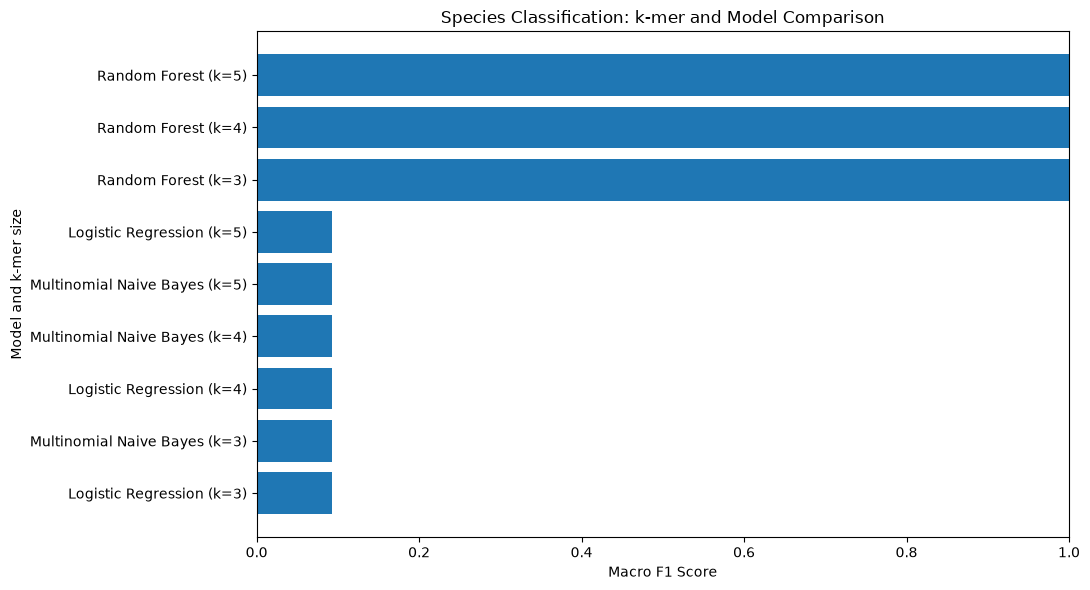

In [20]:

import matplotlib.pyplot as plt

plot_data = results_df.copy()
plot_data["Experiment"] = (
    plot_data["Model"] + " (k=" + plot_data["k"].astype(str) + ")"
)

plot_data = plot_data.sort_values("Macro F1")

plt.figure(figsize=(11, 6))
plt.barh(plot_data["Experiment"], plot_data["Macro F1"])
plt.xlabel("Macro F1 Score")
plt.ylabel("Model and k-mer size")
plt.title("Species Classification: k-mer and Model Comparison")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


In [21]:

best_result = results_sorted.iloc[0]

best_k = int(best_result["k"])
best_model_name = best_result["Model"]
best_model = trained_models[(best_k, best_model_name)]

best_vectorizer = vectorizers[best_k]

X_train_best = normalize(
    best_vectorizer.transform(X_train), norm="l1", axis=1
)
X_test_best = normalize(
    best_vectorizer.transform(X_test), norm="l1", axis=1
)

y_pred_best = best_model.predict(X_test_best)

print("Best k-mer size:", best_k)
print("Best model:", best_model_name)
print("\nClassification report:")
print(classification_report(y_test, y_pred_best, zero_division=0))

labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred_best, labels=labels)

cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)

print("Confusion matrix:")
display(cm_df)


Best k-mer size: 3
Best model: Random Forest

Classification report:
                       precision    recall  f1-score   support

      Neoscona theisi       1.00      1.00      1.00        21
       Oxyopes azhari       1.00      1.00      1.00        14
Oxyopes hindostanicus       1.00      1.00      1.00        15
       Oxyopes oryzae       1.00      1.00      1.00         9
     Wadicosa fidelis       1.00      1.00      1.00        10

             accuracy                           1.00        69
            macro avg       1.00      1.00      1.00        69
         weighted avg       1.00      1.00      1.00        69

Confusion matrix:


,Neoscona theisi,Oxyopes azhari,Oxyopes hindostanicus,Oxyopes oryzae,Wadicosa fidelis
Neoscona theisi,21,0,0,0,0
Oxyopes azhari,0,14,0,0,0
Oxyopes hindostanicus,0,0,15,0,0
Oxyopes oryzae,0,0,0,9,0
Wadicosa fidelis,0,0,0,0,10


In [22]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for k in [3, 4, 5]:

    pipeline = make_pipeline(
        CountVectorizer(
            analyzer="char",
            ngram_range=(k, k),
            lowercase=False
        ),
        Normalizer(norm="l1"),
        RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        )
    )

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "macro_f1": "f1_macro"
        },
        return_train_score=True
    )

    cv_results.append({
        "k": k,
        "Mean training accuracy": scores["train_accuracy"].mean(),
        "Mean validation accuracy": scores["test_accuracy"].mean(),
        "Mean validation macro F1": scores["test_macro_f1"].mean(),
        "Validation accuracy std": scores["test_accuracy"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(3))


,k,Mean training accuracy,Mean validation accuracy,Mean validation macro F1,Validation accuracy std
0,3,1.0,1.0,1.0,0.0
1,4,1.0,1.0,1.0,0.0
2,5,1.0,1.0,1.0,0.0


In [23]:

baseline = DummyClassifier(strategy="most_frequent")

baseline_scores = cross_validate(
    baseline,
    X,
    y,
    cv=cv,
    scoring=["accuracy", "f1_macro"]
)

print(
    "Baseline mean accuracy:",
    round(baseline_scores["test_accuracy"].mean(), 3)
)

print(
    "Baseline mean macro F1:",
    round(baseline_scores["test_f1_macro"].mean(), 3)
)


Baseline mean accuracy: 0.297
Baseline mean macro F1: 0.091


In [24]:

from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import Normalizer
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=123
)

stability_results = []

for k in [3, 4, 5]:

    pipeline = make_pipeline(
        CountVectorizer(
            analyzer="char",
            ngram_range=(k, k),
            lowercase=False
        ),
        Normalizer(norm="l1"),
        RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        )
    )

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=repeated_cv,
        scoring={
            "accuracy": "accuracy",
            "macro_f1": "f1_macro"
        }
    )

    stability_results.append({
        "k": k,
        "Mean accuracy": scores["test_accuracy"].mean(),
        "Std accuracy": scores["test_accuracy"].std(),
        "Minimum accuracy": scores["test_accuracy"].min(),
        "Maximum accuracy": scores["test_accuracy"].max(),
        "Mean macro F1": scores["test_macro_f1"].mean()
    })

stability_df = pd.DataFrame(stability_results)

display(stability_df.round(3))


,k,Mean accuracy,Std accuracy,Minimum accuracy,Maximum accuracy,Mean macro F1
0,3,1.0,0.0,1.0,1.0,1.0
1,4,1.0,0.0,1.0,1.0,1.0
2,5,1.0,0.0,1.0,1.0,1.0


Cross-validated accuracy: 1.0
Cross-validated macro F1: 1.0

Classification report:
                       precision    recall  f1-score   support

      Neoscona theisi       1.00      1.00      1.00       102
       Oxyopes azhari       1.00      1.00      1.00        71
Oxyopes hindostanicus       1.00      1.00      1.00        75
       Oxyopes oryzae       1.00      1.00      1.00        45
     Wadicosa fidelis       1.00      1.00      1.00        51

             accuracy                           1.00       344
            macro avg       1.00      1.00      1.00       344
         weighted avg       1.00      1.00      1.00       344



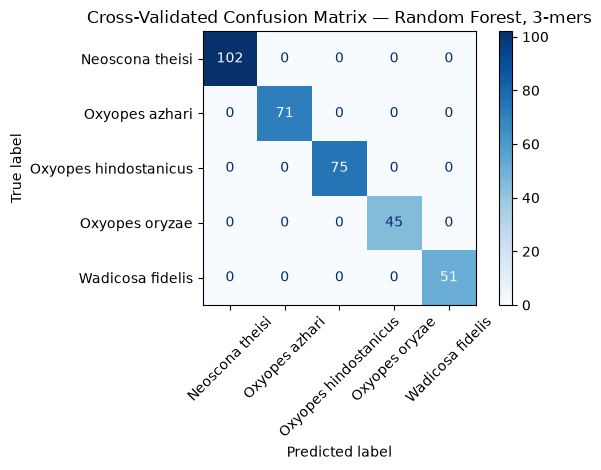

In [25]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import Normalizer
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

# Use 3-mers for the final evaluation
final_pipeline = make_pipeline(
    CountVectorizer(
        analyzer="char",
        ngram_range=(3, 3),
        lowercase=False
    ),
    Normalizer(norm="l1"),
    RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    )
)

# Generate out-of-fold predictions
y_cv_pred = cross_val_predict(
    final_pipeline,
    X,
    y,
    cv=cv
)

print("Cross-validated accuracy:",
      round(accuracy_score(y, y_cv_pred), 3))

print("Cross-validated macro F1:",
      round(f1_score(y, y_cv_pred, average="macro"), 3))

print("\nClassification report:")
print(classification_report(y, y_cv_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y,
    y_cv_pred,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Cross-Validated Confusion Matrix — Random Forest, 3-mers")
plt.tight_layout()
plt.show()
